**INTELIGENCIA ARTIFICIAL CON PYTHON SEMANA 3:**
*Regresión Multivariable*

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount("/content/drive",force_remount=True)

Mounted at /content/drive


In [ ]:
path="/content/drive/MyDrive/Classroom/Inteligencia Artificial con Python Aprendizaje Automático/Precio_Depas.xlsx"
raw_data=pd.read_excel(path,sheet_name="Lince")
dataset=raw_data.copy()
dataset.head(7)


,Baños,Dormitorios,Tamaño,Precio
0,1,1,41,316386
1,1,1,42,310398
2,1,1,37,278472
3,2,2,53,444698
4,2,2,58,447596
5,2,3,61,488195
6,2,3,62,455085


In [ ]:
data_train=dataset.sample(frac=0.8,random_state=0)
data_test=dataset.drop(data_train.index)

print("Data de entrenamiento: \n",data_train)
print("Data de testeo: \n",data_test)

Data de entrenamiento: 
     Baños  Dormitorios  Tamaño   Precio
5       2            3      61   488195
2       1            1      37   278472
19      2            3      79   655464
16      2            3      70   494760
11      2            2      58   412158
22      3            3      89   814399
17      3            3      99   762600
24      4            3     120  1068693
23      2            3      79   622690
14      2            2      64   450120
1       1            1      42   310398
10      2            2      59   427987
13      2            3      61   447142
8       1            1      39   277784
6       2            3      62   455085
18      3            4     111   840720
4       2            2      58   447596
9       1            1      40   295780
7       2            3      79   430000
20      2            3      79   671851
Data de testeo: 
     Baños  Dormitorios  Tamaño  Precio
0       1            1      41  316386
3       2            2      53  444698


In [ ]:
#Entradas de entrenamiento -> data_train
#Salidas de entrenamiento -> train_outputs
train_outputs=data_train.pop("Precio")

#Entradas de testeo -> data_test
#Salidas de testeo -> test_outputs
test_outputs=data_test.pop("Precio")

In [ ]:
print("Entradas de entrenamiento:\n",data_train)
print("Salidas de entrenamiento:\n",train_outputs)

Entradas de entrenamiento:
     Baños  Dormitorios  Tamaño
5       2            3      61
2       1            1      37
19      2            3      79
16      2            3      70
11      2            2      58
22      3            3      89
17      3            3      99
24      4            3     120
23      2            3      79
14      2            2      64
1       1            1      42
10      2            2      59
13      2            3      61
8       1            1      39
6       2            3      62
18      3            4     111
4       2            2      58
9       1            1      40
7       2            3      79
20      2            3      79
Salidas de entrenamiento:
 5      488195
2      278472
19     655464
16     494760
11     412158
22     814399
17     762600
24    1068693
23     622690
14     450120
1      310398
10     427987
13     447142
8      277784
6      455085
18     840720
4      447596
9      295780
7      430000
20     671851
Name: Precio, 

In [ ]:
train_stats=data_train.describe()
train_stats=train_stats.transpose()
print(train_stats)

             count   mean        std   min   25%   50%   75%    max
Baños         20.0   2.05   0.759155   1.0   2.0   2.0   2.0    4.0
Dormitorios   20.0   2.45   0.887041   1.0   2.0   3.0   3.0    4.0
Tamaño        20.0  69.30  23.058507  37.0  58.0  63.0  79.0  120.0


In [ ]:
def escala(x):
  return (x-train_stats["mean"])/train_stats["std"]

train_inputs=escala(data_train)
test_inputs=escala(data_test)

print(data_train)
print(train_inputs)

    Baños  Dormitorios  Tamaño
5       2            3      61
2       1            1      37
19      2            3      79
16      2            3      70
11      2            2      58
22      3            3      89
17      3            3      99
24      4            3     120
23      2            3      79
14      2            2      64
1       1            1      42
10      2            2      59
13      2            3      61
8       1            1      39
6       2            3      62
18      3            4     111
4       2            2      58
9       1            1      40
7       2            3      79
20      2            3      79
       Baños  Dormitorios    Tamaño
5  -0.065863     0.620039 -0.359954
2  -1.383117    -1.634648 -1.400785
19 -0.065863     0.620039  0.420669
16 -0.065863     0.620039  0.030358
11 -0.065863    -0.507305 -0.490058
22  1.251392     0.620039  0.854348
17  1.251392     0.620039  1.288028
24  2.568647     0.620039  2.198755
23 -0.065863     0.620039

In [ ]:
#Modelo con redes neuronales

modelo=keras.Sequential([ layers.Dense(32,input_shape=[3],activation="relu"),
                          layers.Dense(32,activation="relu"),
                          layers.Dense(1)
                         ])

from tensorflow.keras import backend as K

def rmse(y_true,y_pred):
  return K.sqrt(K.mean(K.square(y_true-y_pred)))

#loss= "mae","mse"
op=tf.keras.optimizers.RMSprop(0.01)
modelo.compile(optimizer=op,loss=["mae"],metrics=[rmse])


In [ ]:
modelo.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                128       
                                                                 
 dense_1 (Dense)             (None, 32)                1056      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 1,217
Trainable params: 1,217
Non-trainable params: 0
_________________________________________________________________


In [ ]:
history=modelo.fit(train_inputs,train_outputs,epochs=2000,validation_split=0.2)

Epoch 1/2000
1/1 [==============================] - 1s 1s/step - loss: 550416.3750 - rmse: 592028.4375 - val_loss: 461305.4375 - val_rmse: 480652.5625
Epoch 2/2000
1/1 [==============================] - 0s 38ms/step - loss: 550415.3750 - rmse: 592027.5000 - val_loss: 461304.2500 - val_rmse: 480651.5312
Epoch 3/2000
1/1 [==============================] - 0s 31ms/step - loss: 550414.1250 - rmse: 592026.3125 - val_loss: 461302.7812 - val_rmse: 480650.2500
Epoch 4/2000
1/1 [==============================] - 0s 31ms/step - loss: 550412.5000 - rmse: 592024.8125 - val_loss: 461300.8125 - val_rmse: 480648.5625
Epoch 5/2000
1/1 [==============================] - 0s 32ms/step - loss: 550410.3750 - rmse: 592022.8750 - val_loss: 461298.3438 - val_rmse: 480646.5000
Epoch 6/2000
1/1 [==============================] - 0s 32ms/step - loss: 550407.8750 - rmse: 592020.5000 - val_loss: 461295.4688 - val_rmse: 480644.0938
Epoch 7/2000
1/1 [==============================] - 0s 29ms/step - loss: 550404.7500

In [ ]:
print(history.history.keys())

dict_keys(['loss', 'rmse', 'val_loss', 'val_rmse'])


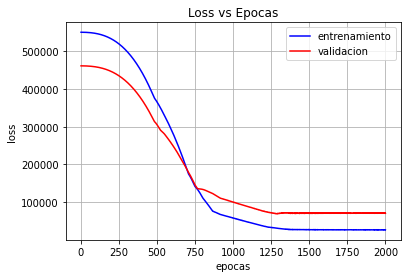

In [ ]:
train_mae=history.history["loss"]
valid_mae=history.history["val_loss"]

epochs=range(1,len(train_mae)+1)

plt.plot(epochs,train_mae,"b-",label="entrenamiento")
plt.plot(epochs,valid_mae,"r-",label="validacion")
plt.legend()
plt.xlabel("epocas")
plt.ylabel("loss")
plt.title("Loss vs Epocas")
plt.grid()
plt.show()

In [ ]:
#Test
print("Entradas: \n",data_test)
print("Salidas Reales: \n",test_outputs)

output_est=modelo.predict(test_inputs)
print("Salidas Estimadas: \n",output_est)

df=pd.DataFrame(output_est)


Entradas: 
     Baños  Dormitorios  Tamaño
0       1            1      41
3       2            2      53
12      1            2      53
15      2            2      62
21      3            3      89
Salidas Reales: 
 0     316386
3     444698
12    381728
15    433380
21    795890
Name: Precio, dtype: int64
Salidas Estimadas: 
 [[281499.78]
 [397821.25]
 [236094.47]
 [442593.56]
 [752847.5 ]]


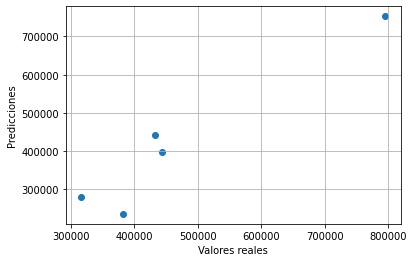

In [ ]:
plt.scatter(test_outputs,output_est)
plt.xlabel("Valores reales")
plt.ylabel("Predicciones")
plt.grid()
plt.show()

In [ ]:
#Prediccion
df=pd.DataFrame({"Baños":[2,1],"Dormitorios":[4,2],"Tamaño":[75,50]})
print("Data: \n",df)
x_new=escala(df)
precio_pred=modelo.predict(x_new)
print("La predicción del precio es: \n",precio_pred)

Data: 
    Baños  Dormitorios  Tamaño
0      2            4      75
1      1            2      50
La predicción del precio es: 
 [[534730.44]
 [226821.08]]
